In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Фіксація seed за номером варіанта (1)
np.random.seed(1)

days = np.arange(1, 31)
# Умовно вихідні дні (кожні субота й неділя, приблизно кожен 6-7 день)
weekend = np.isin(days % 7, [6, 0])

# Температура: середня 32°C з невеликим відхиленням ±3°C
temperature = np.round(np.random.normal(32, 1.5, size=30), 1)

# Продажі: базові 40 + вищі продажі у вихідні дні (+ випадоковий шум)
base_sales = 40
sales = np.round(
    base_sales + weekend * np.random.uniform(6, 12, size=30) + np.random.normal(0, 3, size=30)
).astype(int)

df_sales = pd.DataFrame({
    "день": days,
    "вихідний": weekend,
    "температура": temperature,
    "продажі": sales
})

print("Перші рядки згенерованого набору:")
display(df_sales.head())

Перші рядки згенерованого набору:


,день,вихідний,температура,продажі
0,1,False,34.4,43
1,2,False,31.1,43
2,3,False,31.2,41
3,4,False,30.4,43
4,5,False,33.3,38


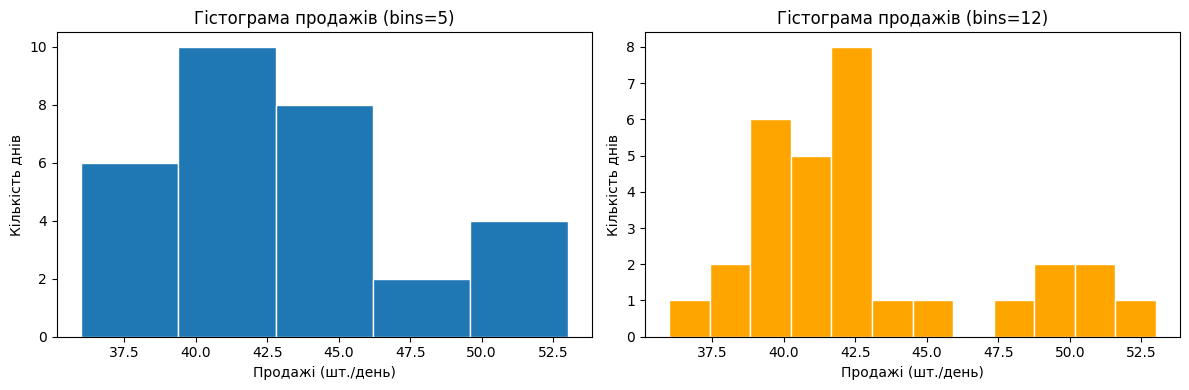

In [40]:
# Побудова двох гістограм із різною кількістю інтервалів (bins)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.hist(df_sales["продажі"], bins=5, edgecolor="white")
ax1.set_xlabel("Продажі (шт./день)")
ax1.set_ylabel("Кількість днів")
ax1.set_title("Гістограма продажів (bins=5)")

ax2.hist(df_sales["продажі"], bins=12, edgecolor="white", color="orange")
ax2.set_xlabel("Продажі (шт./день)")
ax2.set_ylabel("Кількість днів")
ax2.set_title("Гістограма продажів (bins=12)")

plt.tight_layout()
plt.show()

/tmp/ipykernel_5537/606314497.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([weekday_sales, weekend_sales], labels=["Будні дні", "Вихідні дні"])


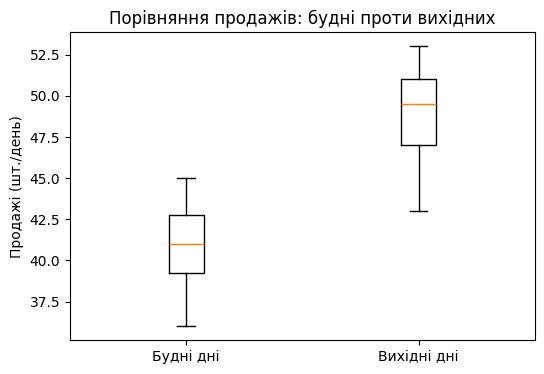

In [41]:
fig, ax = plt.subplots(figsize=(6, 4))

weekday_sales = df_sales.loc[~df_sales["вихідний"], "продажі"]
weekend_sales = df_sales.loc[df_sales["вихідний"], "продажі"]

ax.boxplot([weekday_sales, weekend_sales], labels=["Будні дні", "Вихідні дні"])
ax.set_ylabel("Продажі (шт./день)")
ax.set_title("Порівняння продажів: будні проти вихідних")
plt.show()

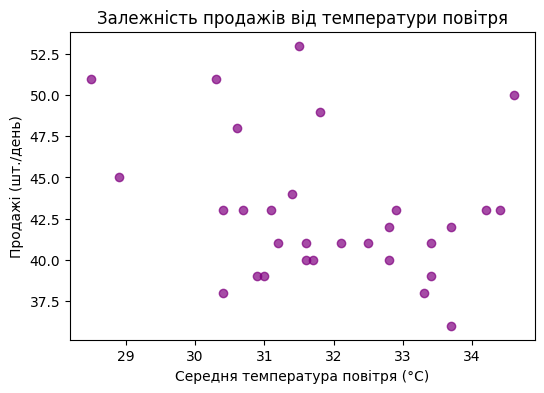

In [42]:
fig, ax = plt.subplots(figsize=(6, 4))

ax.scatter(df_sales["температура"], df_sales["продажі"], color="purple", alpha=0.7)
ax.set_xlabel("Середня температура повітря (°C)")
ax.set_ylabel("Продажі (шт./день)")
ax.set_title("Залежність продажів від температури повітря")
plt.show()

/tmp/ipykernel_5537/1498055146.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax_correct.boxplot(groups, labels=["Будні", "Вихідні"])
/tmp/ipykernel_5537/1498055146.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax_distorted.boxplot(groups, labels=["Будні", "Вихідні"])


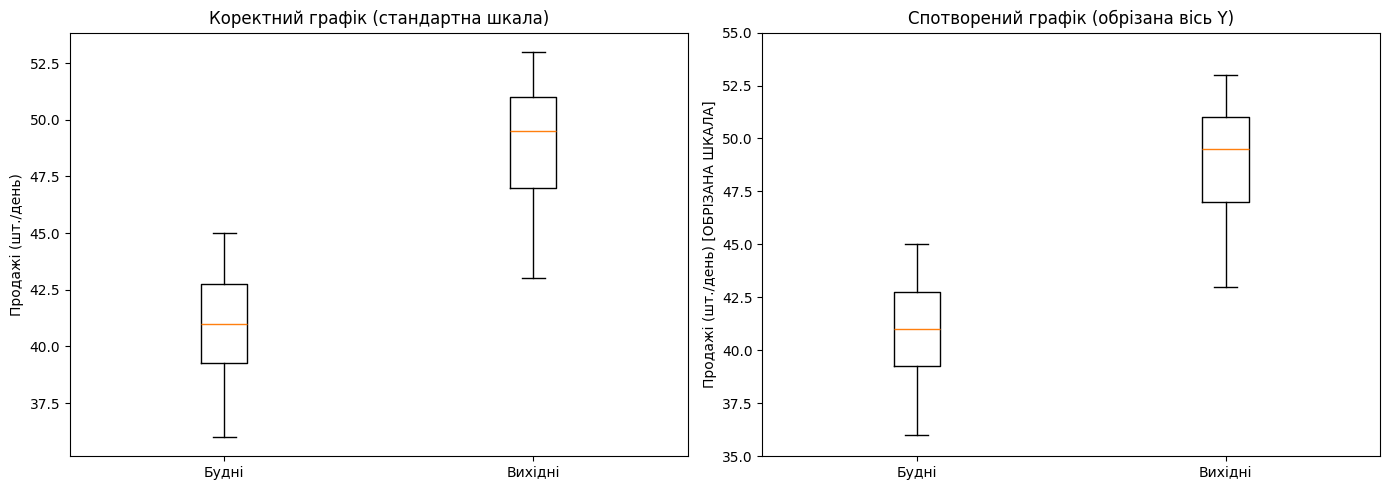

In [43]:
fig, (ax_correct, ax_distorted) = plt.subplots(1, 2, figsize=(14, 5))

groups = [weekday_sales, weekend_sales]

# 1. Коректний графік (з повною шкалою від нуля або стандартного мінімуму)
ax_correct.boxplot(groups, labels=["Будні", "Вихідні"])
ax_correct.set_ylabel("Продажі (шт./день)")
ax_correct.set_title("Коректний графік (стандартна шкала)")

# 2. Спотворений графік (штучно обрізана вісь Y)
ax_distorted.boxplot(groups, labels=["Будні", "Вихідні"])
ax_distorted.set_ylim(35, 55)  # штучне обмеження шкали знизу
ax_distorted.set_ylabel("Продажі (шт./день) [ОБРІЗАНА ШКАЛА]")
ax_distorted.set_title("Спотворений графік (обрізана вісь Y)")

plt.tight_layout()
plt.show()

### Відповіді на контрольні запитання:

1. **Чому обрізана вісь Y на стовпчиковій діаграмі перебільшує різницю між категоріями:**
   - Обрізання осі Y приховує справжню базову точку відліку (часто нуль), через що мінімальні відмінності в числових значеннях починають займати значну вертикальну площу графічних елементів (стовпчиків чи ящиків). Це створює у спостерігача оманливе враження критично величезного розриву між показниками, хоча підписані цифри залишаються математично правильними.

2. **Приклад, коли лінійний графік є методологічною помилкою для категоріальних даних:**
   - Побудова лінійного графіка (з'єднання точок лініями) є помилкою для номінальних або порядкових категоріальних даних (наприклад, назви міст чи групи товарів), оскільки лінія передбачає неперервний перехід і проміжні значення між категоріями, яких фізично не існує (наприклад, неможливо «проіснувати» стан між Києвом і Львовом на осі міст).

3. **Чому підписи осей, одиниці й заголовок — частина твердження графіка, а не оздоблення:**
   - Графік без чітких підписів та одиниць вимірювання позбавлений контексту і може трактуватися двозначно. Заголовок задає головну тезу або висновок візуалізації, а підписи осей визначають масштаб і фізичний сенс величин, перетворюючи сирі геометричні фігури на обґрунтоване наукове чи аналітичне твердження.

4. **Що таке chartjunk та чому він шкодить сприйняттю:**
   - **Chartjunk** (надмірний «візуальний сміття» на кшталт непотрібних 3D-ефектів, складних текстур, зайвих фонових сіток чи анімацій) відволікає увагу глядача від самих даних, створює когнітивне перевантаження та часто спотворює пропорції об'єктів (перспективні спотворення в 3D), ускладнюючи швидке й точне зчитування інформації.